# Intro

## Global parameters

In [1]:
MAX_TIME_HOURS=1
ALPHA=0.01
_PVAL_FLOOR=10**-6

## Modules

### Standard

In [2]:
import os, pickle, platform, sys
import numpy as np
import copy
import torch

In [3]:
from collections import defaultdict

In [4]:
import dcms
from dcms.models import DCMModel, DECMModel, qDECMModel, DWCMModel

In [5]:
import matplotlib.pyplot as plt
plt.rcParams['axes.linewidth'] = 2
plt.rcParams['xtick.major.size'] = 10
plt.rcParams['xtick.major.width'] = 2
plt.rcParams['ytick.major.size'] = 10
plt.rcParams['ytick.major.width'] = 2

plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14

plt.rcParams['xtick.minor.size'] = 5
plt.rcParams['xtick.minor.width'] = 1
plt.rcParams['ytick.minor.size'] = 5
plt.rcParams['ytick.minor.width'] = 1
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
from matplotlib.ticker import ScalarFormatter

In [6]:
from scipy.stats import spearmanr

In [7]:
from tqdm.notebook import tqdm, trange

In [8]:
import datetime as dt

In [9]:
from bowtie import edges2bowtie

In [10]:
from tabulate import tabulate

### Home made

In [11]:
if platform.system() == 'Darwin':
    print('Air!')
    HOME = '/Users/fabio/Documents/Lavoro/PythonFiles/bowtie2_py310/bowtie2/'
elif platform.system() == 'Linux':
    print('Stella!')
    HOME = '/home/sarawalk/bowtie2_py39/bowtie2/'
else:
    raise RuntimeError(f"Unsupported OS: {platform.system()}")

sys.path.insert(0, HOME)

Air!


In [12]:
from auxiliary_functions import el2ks, bic

In [13]:
from sam_bowtie import block_and_fluxes as bnf

In [14]:
from bowtie_plot_functions import plot_bowtie_blocks, plot_bowtie_fluxes, _add_colorbar
from bowtie_plot_functions import _fdr as fdr

## Load data

In [15]:
DATA_FOLDER=HOME+'dati_elezioni/'
TEST_FOLDER=HOME+'tests/'
PVALUE_FOLDER=HOME+'pvalues/'
GUARINO_FOLDER=HOME+'guarino_files/'
BIPARTITE_FOLDER=HOME+'BiDCM/'
PLOT_FOLDER=HOME+'plots/'

## Names for $\LaTeX$
#### Names as in the draft

In [16]:
def parse_dico_names(filepath):
    with open(filepath, 'r') as f:
        lines = [line.strip().split() for line in f]
        # such a command creates a list
        # in which each element is a list of tokens of a line in the file
        # remarkably, there is an empty element
        # before each dataset name
        

    result = {}
    current_key = None

    for tokens in lines:
        if not tokens:
            current_key = None
        elif current_key is None:
            # prima riga non vuota del gruppo: nome del dataset
            current_key = tokens[0]
            result[current_key] = {}
        else:
            # riga tipo ['5:', 'journalists', '&', 'Media']
            idx = int(tokens[0].rstrip(':'))
            label = ' '.join(tokens[1:])
            result[current_key][idx] = label

    return result

In [17]:
cacca=parse_dico_names(GUARINO_FOLDER+'all_dico_labels.txt')

In [18]:
cacca['quirinale']

{5: 'journalists & Media',
 2: 'M5S',
 0: 'journalists & IV & Azione & +Europa & Media',
 4: 'Lega & FDI',
 1: 'PD',
 3: 'Media & journalists',
 6: 'FI'}

In [19]:
name_changer={'c0': 'Crisis - Centrists', 'c1': 'Crisis - Centre-right', 'c2': 'Crisis - M5S', 'c3': 'Crisis - PD', 'c4': 'Crisis - Media', 'e0': 'Elections - Centre-right', 'e1': 'Elections - Centre-left', 'e2': 'Elections - M5S', 'e3': 'Elections - Centrists', 'e4': 'Elections - Others', 'e5': 'Elections - Media', 'e6': 'Elections - Others 2', 'p0': 'President -  Centrists', 'p1': 'President -  PD', 'p2': 'President -  M5S', 'p3': 'President -  Media', 'p4': 'President -  Right', 'p5': 'President -  Others', 'p6': 'President -  FI'}

#### Proper names for the Latex table

In [20]:
def sci_latex(x, dec=2, bold=False):
    # da Claude
    mant, exp = f'{x:.{dec}e}'.split('e')
    if bold:
        return f'$\\mathbf{{{mant}\\times 10^{{{int(exp)}}}}}$'
    return f'${mant}\\times 10^{{{int(exp)}}}$'


# Where are we?

## Check the files

In [21]:
os.listdir(TEST_FOLDER)

['quirinale_dico0_dwcm_final.pkl',
 'crisi_dico3_qdecm.pkl',
 'batch2608_ita_elections_dico6_decm.pkl',
 'decm_validation',
 'ita_elections_dico3_dwcm_final.pkl',
 'crisi_run9.log',
 'crisi_dico0_dwcm_final.pkl',
 'crisi_dico4_decm.pkl',
 'ita_elections_dico1_decm_conv.pkl',
 'ita_elections_dico4_dwcm_final.pkl',
 'crisis_qdecm_new_theta_nprocs_8.pkl',
 'batch2608_quirinale_dico4_decm.pkl',
 'ita_elections_dico5_dwcm_final.pkl',
 'crisi_dico1_dwcm_final.pkl',
 'quirinale_dico6_dwcm_final.pkl',
 'ita_elections_dico2_dwcm_final.pkl',
 'quirinale_dico1_qdecm.pkl',
 'quirinale_dico1_dwcm_final.pkl',
 'crisi_dico2_decm_and_10_gamma_0.0_hub_0_gauge_min.pkl',
 'ita_elections_dico1_qdecm.pkl',
 'ita_elections_dico0_dwcm_final.pkl',
 'batch2608_quirinale_dico2_decm.pkl',
 'batch2608_quirinale_dico3_decm.pkl',
 'ita_elections_dico3_decm_stella.pkl',
 'quirinale_dico4_decm_conv.pkl',
 'crisi_dico4_dwcm_final.pkl',
 'quirinale_dico3_dwcm_final.pkl',
 'crisi_dico2_qdecm.pkl',
 'crisi_run_symgs.log'

## Get all converged solutions

In [22]:
solution_files=[f for f in os.listdir(TEST_FOLDER) if f.endswith('.pkl')]
solution_files.sort()

In [23]:
final_dict={}
for solution in solution_files:
    # get the model type from the solution filename
    if 'qdecm' in solution.lower():
        model_type='qDECM'
    elif 'decm' in solution.lower():
        model_type='DECM'
    elif 'dwcm' in solution.lower():
        model_type='DWCM'
    else:
        print(f"Unknown model type in solution {solution}. Skipping.")
        continue

    # get the dataset from the solution filename
    if 'elections' in solution.lower():
        name='e'
    elif 'crisi' in solution.lower():
        name='c'
    elif 'quirinale' in solution.lower():
        name='p'
    else:
        print(f"Unknown dataset in solution {solution}. Skipping.")
        continue
    
    try:
        i_dico=solution.index('dico')
        dico=solution[i_dico+4]
    except ValueError:
        print(f"No 'dico' found in solution {solution}. Skipping.")
        continue

    dataset=f"{name}{dico}"
    if os.path.exists(TEST_FOLDER+solution):
        try:
            with open(TEST_FOLDER+solution, 'rb') as f:
                _temp = pickle.load(f)
        except Exception as e:
            print(f"{solution}: Error occurred while loading the solution: {e}. Deleting the file and skipping.")
            os.remove(TEST_FOLDER+solution)
            continue
        try:
            if _temp.sol.mre < 1e-5:  # Check if the model converged
                print(f"{solution}: Model converged.")
                if dataset not in final_dict:
                    final_dict[dataset]={}
                if model_type not in final_dict[dataset]:
                    final_dict[dataset][model_type]=_temp
                else:
                    print(f"{solution}: Converging model already exists in final_dict. Skipping.")
            else:
                print(f"{solution}: Model did not converge.")
        except AttributeError:
            print(f"{solution}: No 'sol' attribute in the loaded data.")

batch2608_crisi_dico1_decm.pkl: Model did not converge.
batch2608_crisi_dico3_decm.pkl: Model converged.
batch2608_crisi_dico4_decm.pkl: Model converged.
batch2608_ita_elections_dico0_decm.pkl: Model did not converge.
batch2608_ita_elections_dico1_decm.pkl: Model did not converge.
batch2608_ita_elections_dico4_decm.pkl: Model converged.
batch2608_ita_elections_dico5_decm.pkl: Model converged.
batch2608_ita_elections_dico6_decm.pkl: Model converged.
batch2608_quirinale_dico0_decm.pkl: Model converged.
batch2608_quirinale_dico1_decm.pkl: Model converged.
batch2608_quirinale_dico2_decm.pkl: Model converged.
batch2608_quirinale_dico3_decm.pkl: Model converged.
batch2608_quirinale_dico4_decm.pkl: Model did not converge.
crisi_dico0_decm_conv.pkl: Model converged.
crisi_dico0_dwcm_final.pkl: Model converged.
crisi_dico0_qdecm.pkl: Model converged.
crisi_dico1_decm_conv.pkl: Model converged.
crisi_dico1_dwcm_final.pkl: Model converged.
crisi_dico1_qdecm.pkl: Model converged.
crisi_dico2_decm.

### Check

In [24]:
_keys=list(final_dict.keys())
_keys.sort()

In [25]:
_three_of_us=[key for key in _keys if len(final_dict[key]) == 3]
_three_of_us

['c0',
 'c1',
 'c2',
 'c3',
 'c4',
 'e0',
 'e1',
 'e2',
 'e3',
 'e4',
 'e5',
 'e6',
 'p0',
 'p1',
 'p2',
 'p3',
 'p4',
 'p5',
 'p6']

In [26]:
len(_three_of_us), len(_keys)

(19, 19)

In [27]:
_decm_sols=[key for key in _keys if 'DECM' in final_dict[key].keys()]
_decm_sols==_three_of_us

True

# DWCM vs. qDECM vs. DECM

### Expected topology comparison

In [28]:
# colors and labels
colors=['orchid','darkorchid']
labels_decm=[r'$p_{DECM}$', r'$\langle w\rangle_{DECM}$']
labels_qdecm=[r'$p_{qDECM}$', r'$\langle w\rangle_{qDECM}$']
labels_dwcm=[r'$p_{DWCM}$', r'$\langle w\rangle_{DWCM}$']

In [29]:
sample_size=10**4

In [30]:
def status(dataset, i, n, msg, width=50):
    print(f"[{dataset}, {i:2d}/{n:2d}] {msg:<{width}}", end='\r')

In [31]:
rng = np.random.default_rng()

  0%|          | 0/19 [00:00<?, ?it/s]

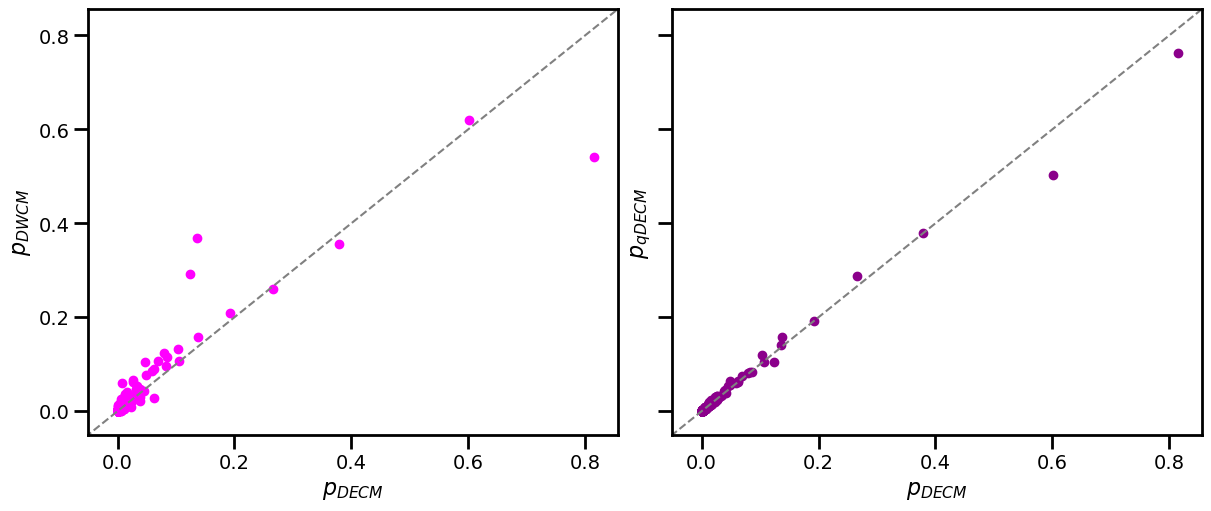

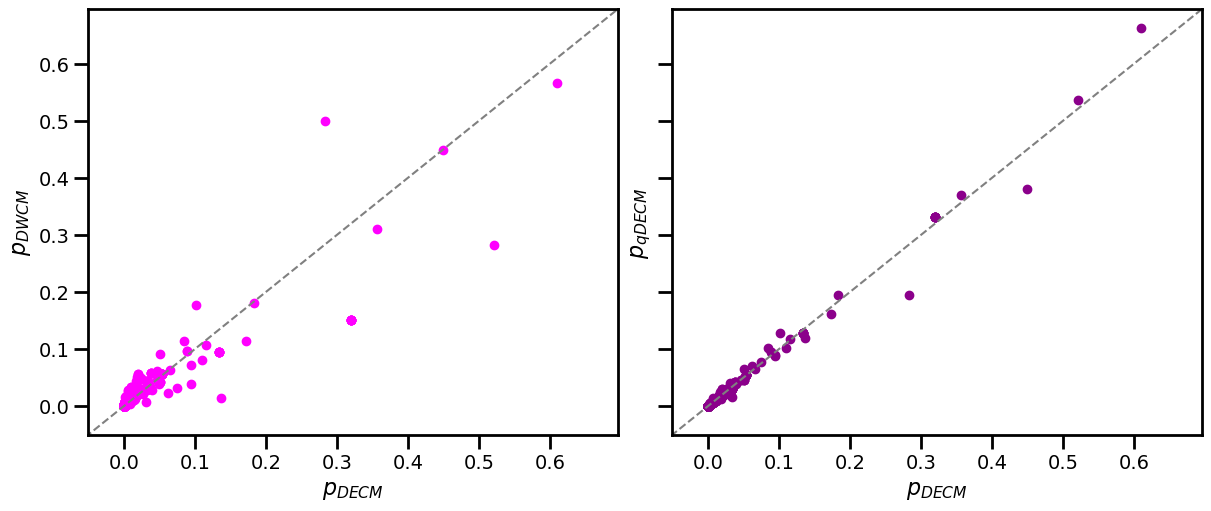

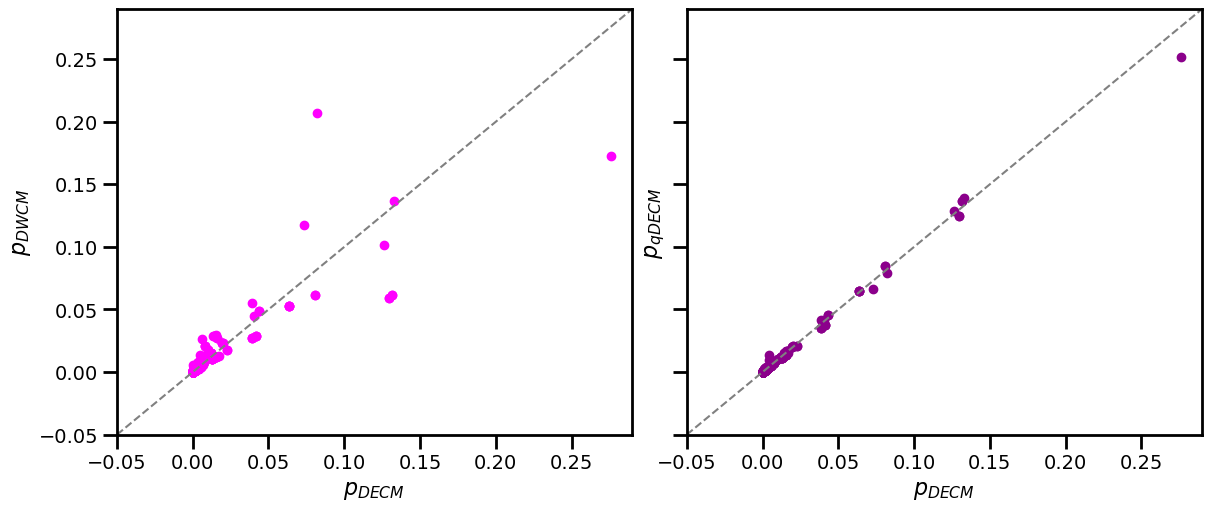

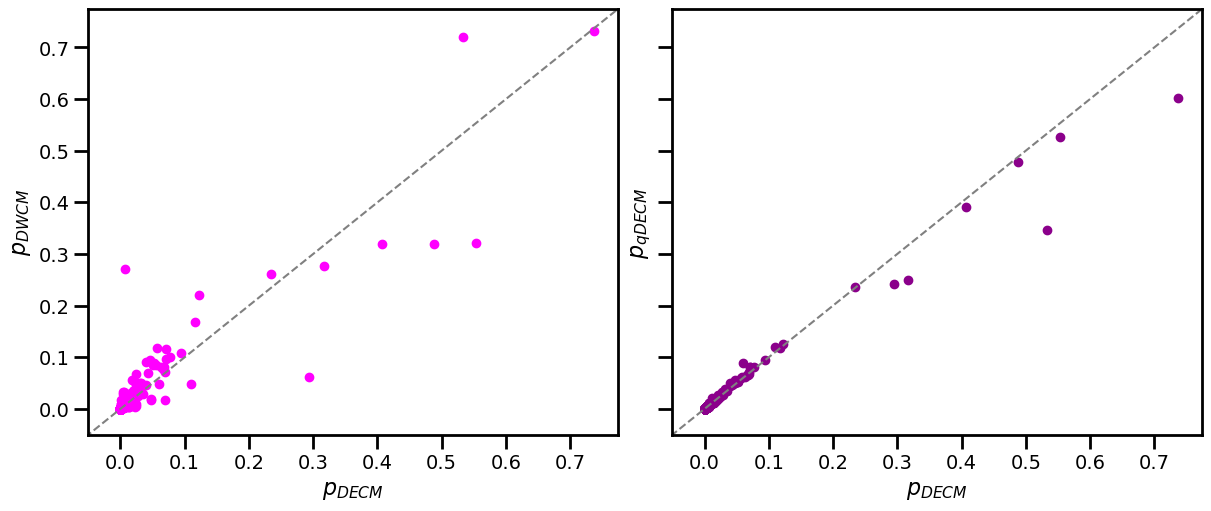

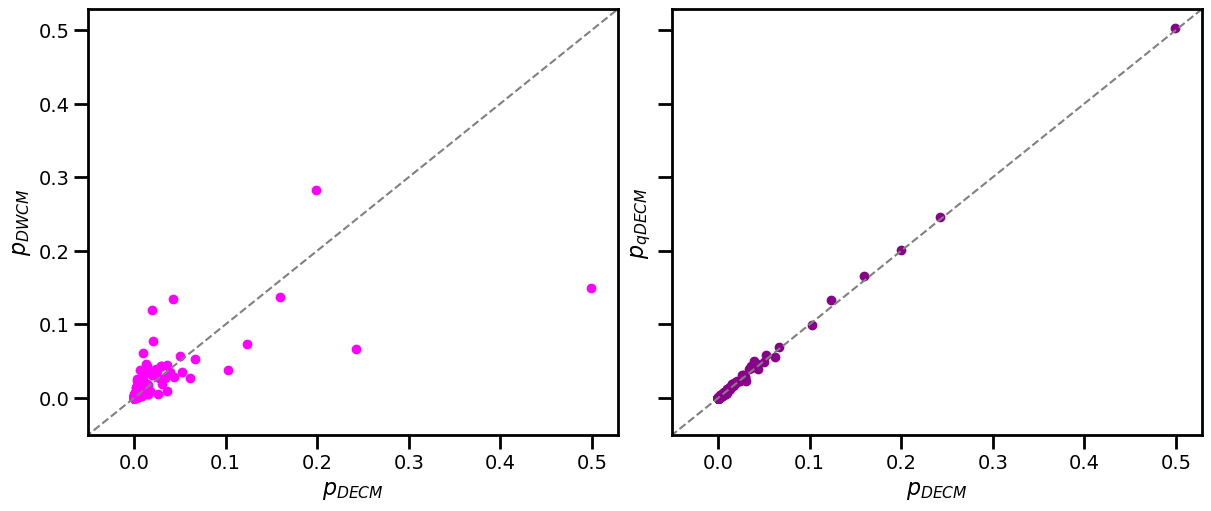

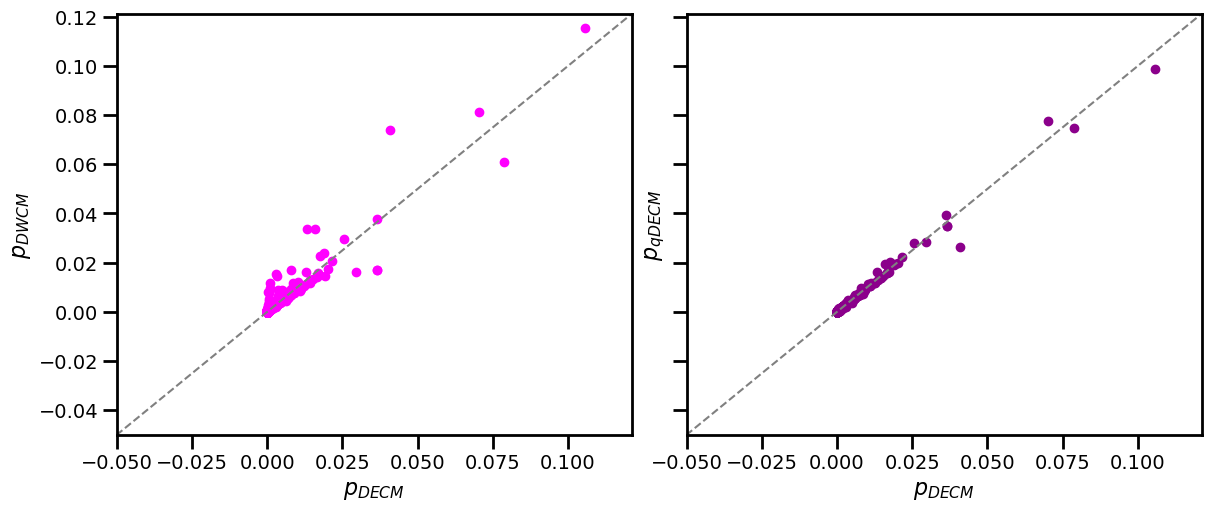

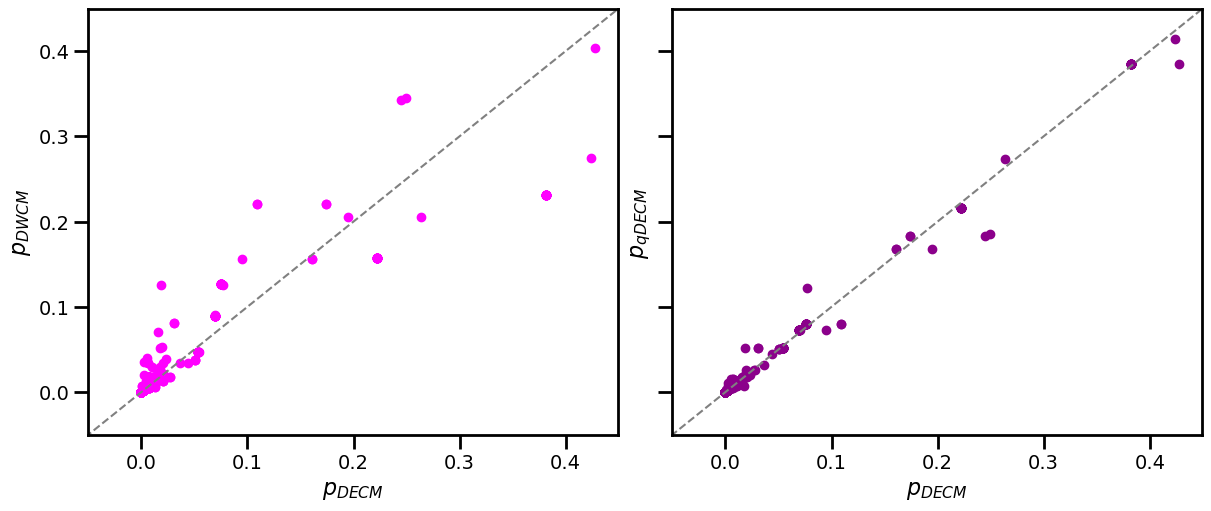

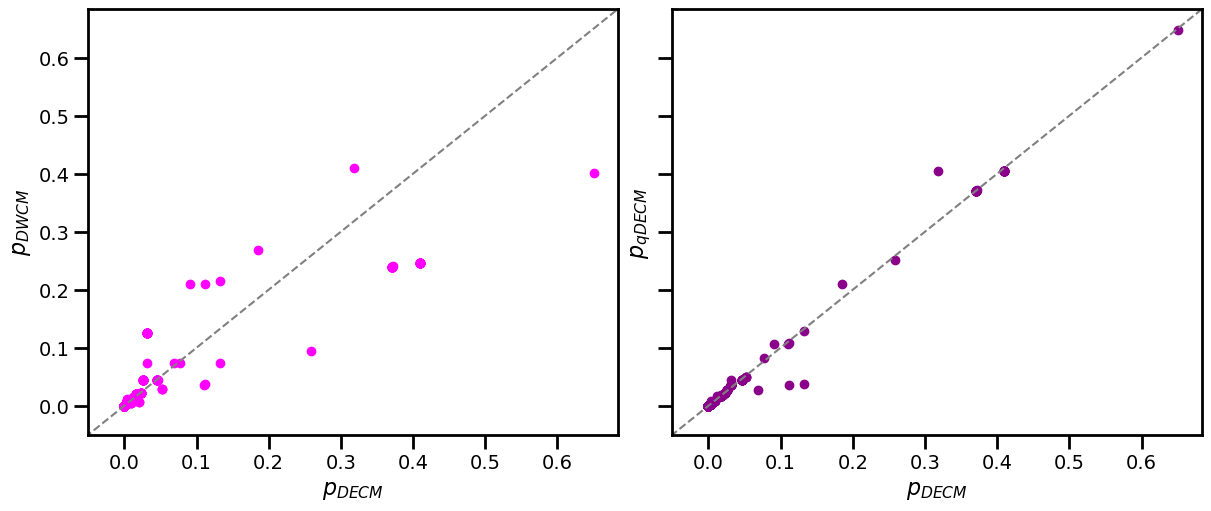

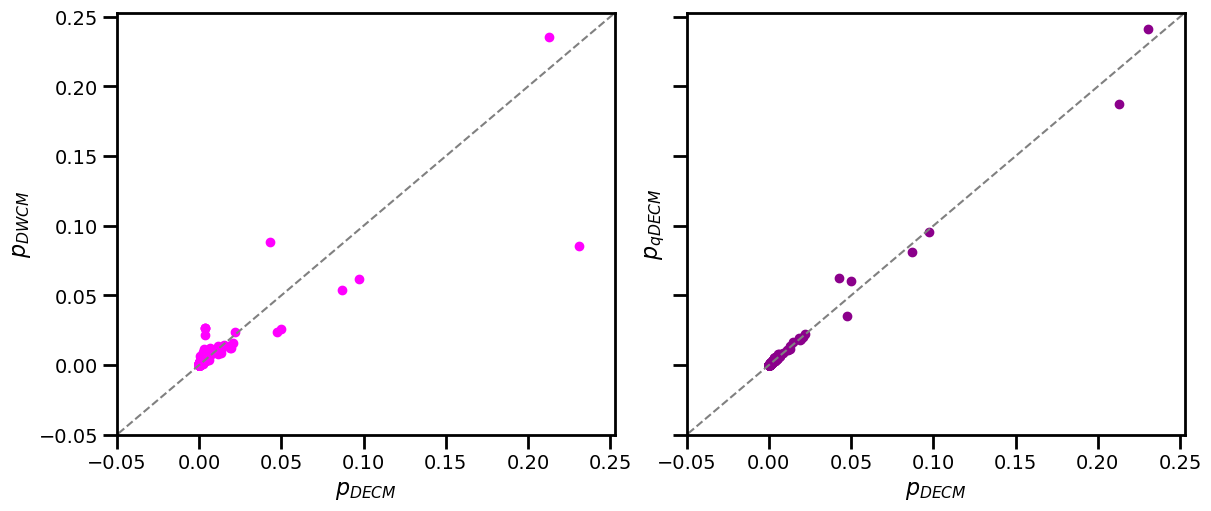

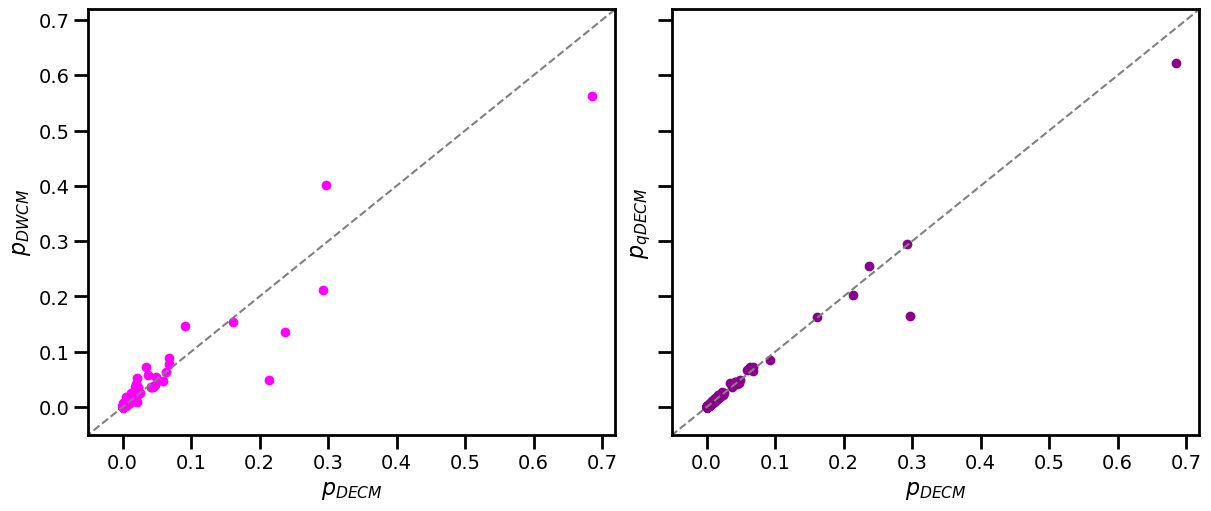

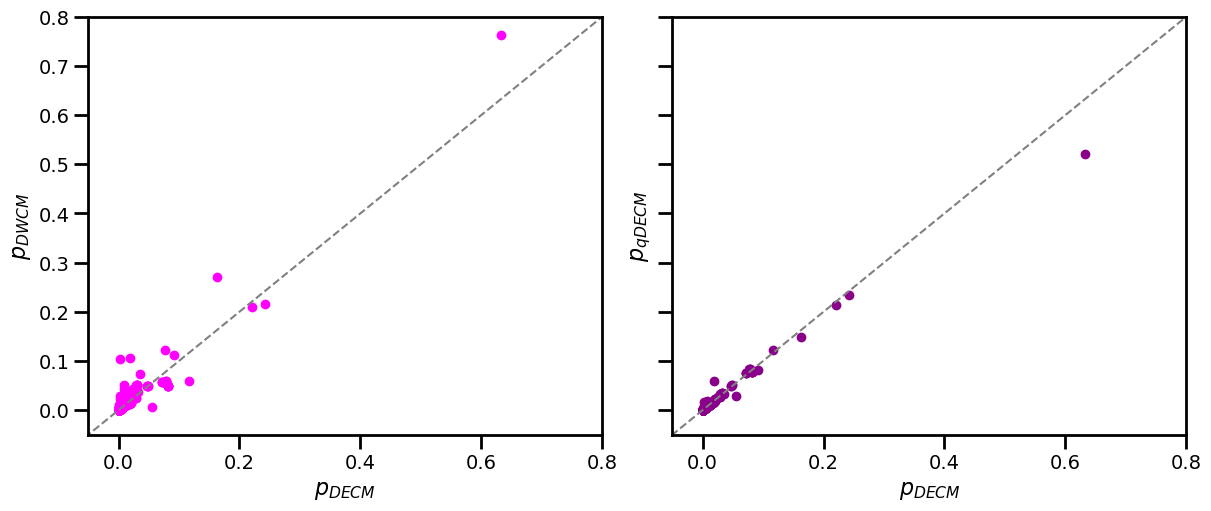

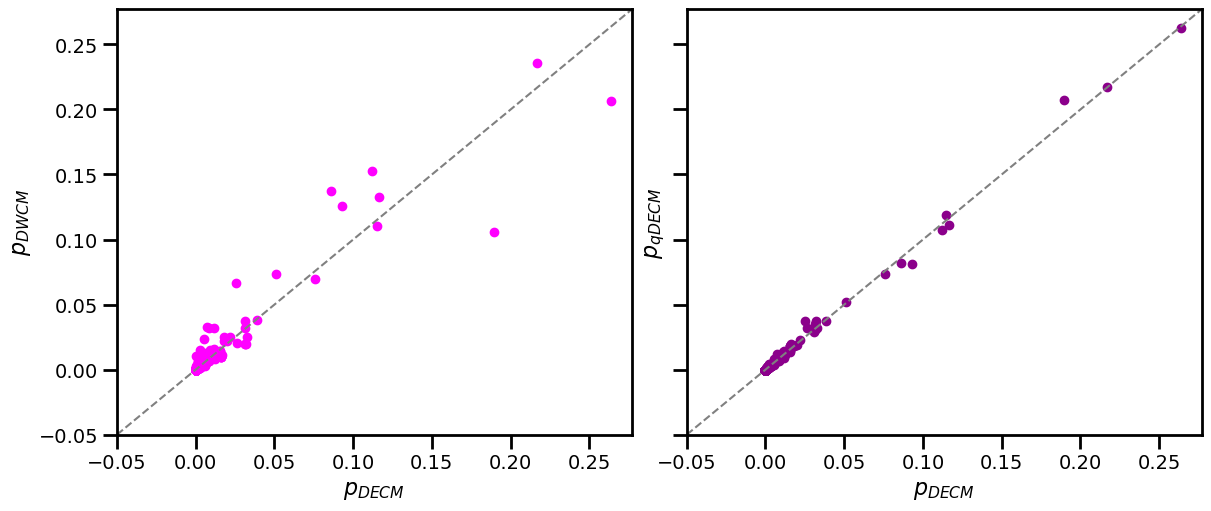

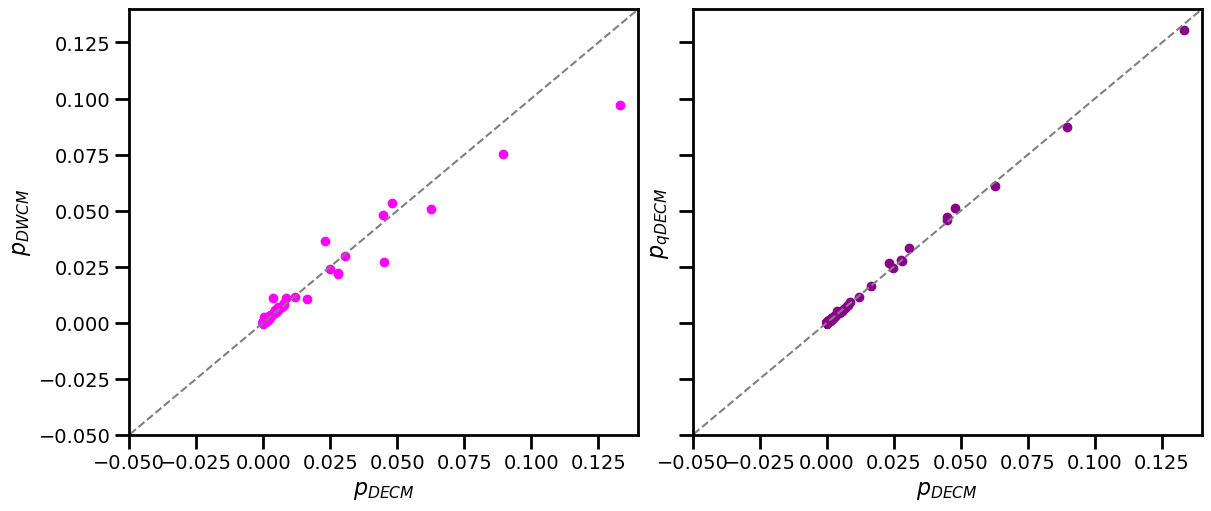

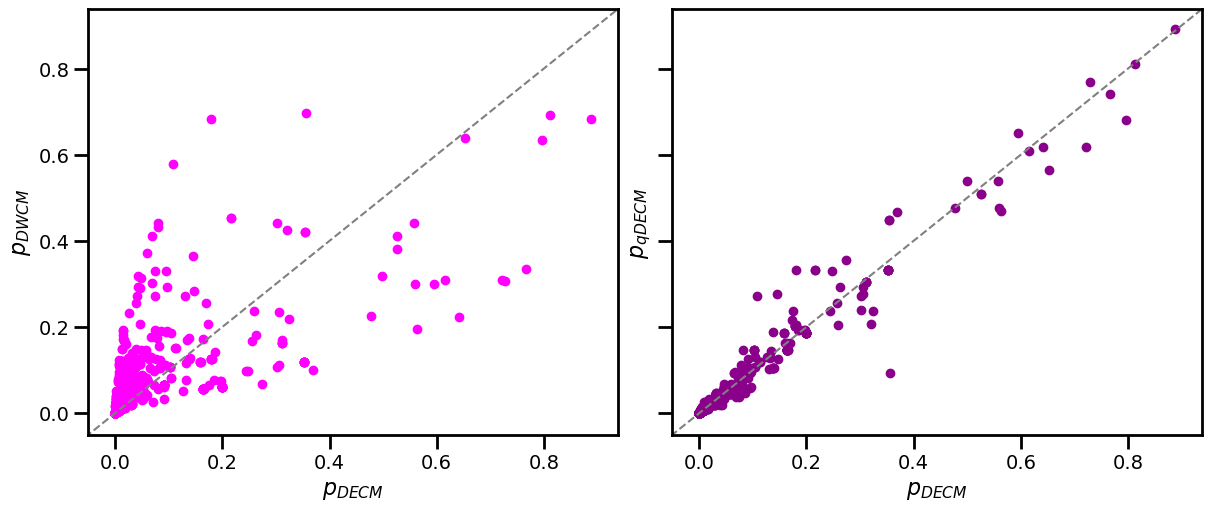

In [33]:
for i in trange(len(_three_of_us)):
    dataset=_three_of_us[i]
    
    
    sol_dict=final_dict[dataset]

    # Check if all three models are present
    if not all(model in sol_dict for model in ['DECM', 'qDECM', 'DWCM']):
        msg="Dataset does not have all three models. Skipping."
        status(dataset, i, len(_three_of_us), msg)
        continue

    # Extract solutions
    decm_sol=sol_dict['DECM']
    qdecm_sol=sol_dict['qDECM']
    dwcm_sol=sol_dict['DWCM']
    N=decm_sol.N

    if N**2>10**9:
        msg=f"N={N:.2e} is too large, skipping dataset..."
        status(dataset, i, len(_three_of_us), msg)
        continue

    msg=f"N={N:.2e} Processing dataset..."
    status(dataset, i, len(_three_of_us), msg)
    # Now you can proceed with your analysis using decm_sol, qdecm_sol, and dwcm_sol
    theta_decm=decm_sol.sol.best_theta
    theta_qdecm=qdecm_sol.sol.best_theta
    theta_dwcm=dwcm_sol.sol.best_theta

    # select some of the entries
    msg=f"N={N:.2e} Selecting entries..."
    status(dataset, i+1, len(_three_of_us), msg)    
    selected_points=rng.choice(N**2, size=sample_size, replace=False)
    

    # probability matrices
    msg="Processing DECM..."
    status(dataset, i+1, len(_three_of_us), msg)    
    p_decm=decm_sol.pij_matrix(theta_decm).flatten()
    p_decm=p_decm[selected_points]

    msg="Processing qDECM..."
    status(dataset, i+1, len(_three_of_us), msg)    
    p_qdecm=qdecm_sol.pij_matrix(theta_qdecm[:2*N]).flatten()
    p_qdecm=p_qdecm[selected_points]

    msg="Processing DWCM..."
    status(dataset, i+1, len(_three_of_us), msg)        
    p_dwcm=dwcm_sol.pij_matrix(theta_dwcm).flatten()
    p_dwcm=p_dwcm[selected_points]

    max_p=np.max([p_decm.max(), p_qdecm.max(), p_dwcm.max()])

    
    msg="Points selected..."
    status(dataset, i+1, len(_three_of_us), msg)
    # plot
    fig, axs= plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True, sharex=True, sharey=True)

    axs[0].scatter(p_decm, p_dwcm, color=colors[0])
    axs[0].plot([-1,2], [-1,2], '--', color='gray')
    axs[0].set_xlim([-0.05, max_p*1.05])
    axs[0].set_ylim([-0.05, max_p*1.05])
    #axs[0].set_xscale('log')
    #axs[0].set_yscale('log')    

    axs[1].scatter(p_decm, p_qdecm, color=colors[1])
    axs[1].plot([-1,10], [-1,10], '--', color='gray')
    axs[1].set_xlim([-0.05, max_p*1.05])
    axs[1].set_ylim([-0.05, max_p*1.05])
    #axs[1].set_xscale('log')
    #axs[1].set_yscale('log')    


    for j in range(2):
        axs[j].set_xlabel(labels_decm[0], fontsize=16)
    axs[0].set_ylabel(labels_dwcm[0], fontsize=16)
    axs[1].set_ylabel(labels_qdecm[0], fontsize=16)
    plt.savefig(PLOT_FOLDER+f"p_comparison_{dataset}.png")
    msg="Plot saved!"
    status(dataset, i+1, len(_three_of_us), msg)

### Expected weights comparison

In [34]:
# colors and labels
colors=['magenta','darkmagenta']
labels_decm=[r'$p_{DECM}$', r'$\langle w\rangle_{DECM}$']
labels_qdecm=[r'$p_{qDECM}$', r'$\langle w\rangle_{qDECM}$']
labels_dwcm=[r'$p_{DWCM}$', r'$\langle w\rangle_{DWCM}$']

In [35]:
sample_size=10**4

In [36]:
def status(dataset, i, n, msg, width=50):
    print(f"[{dataset}, {i:2d}/{n:2d}] {msg:<{width}}", end='\r')

In [37]:
rng = np.random.default_rng()

  0%|          | 0/19 [00:00<?, ?it/s]

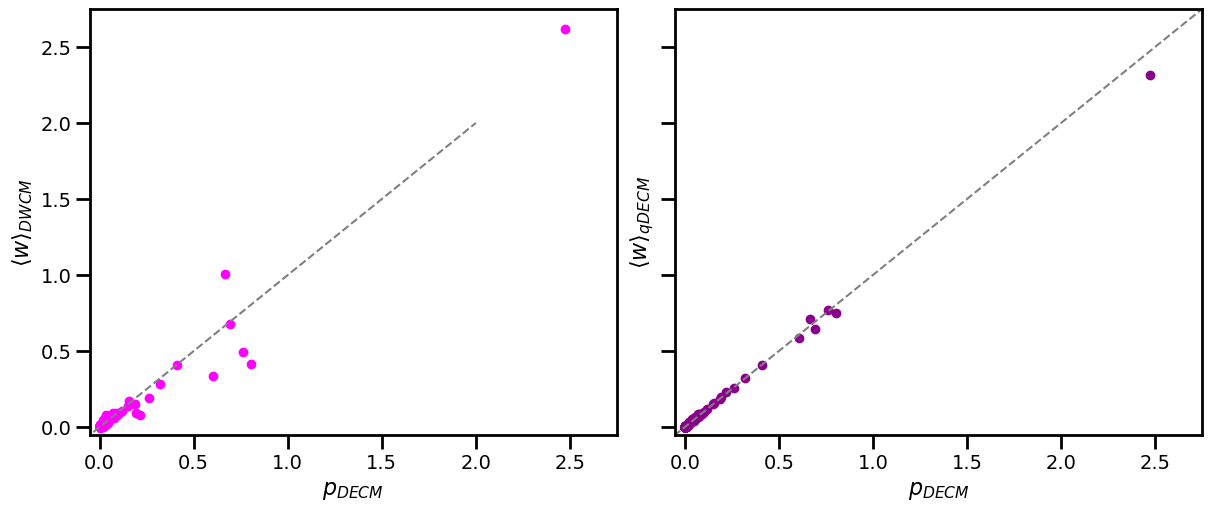

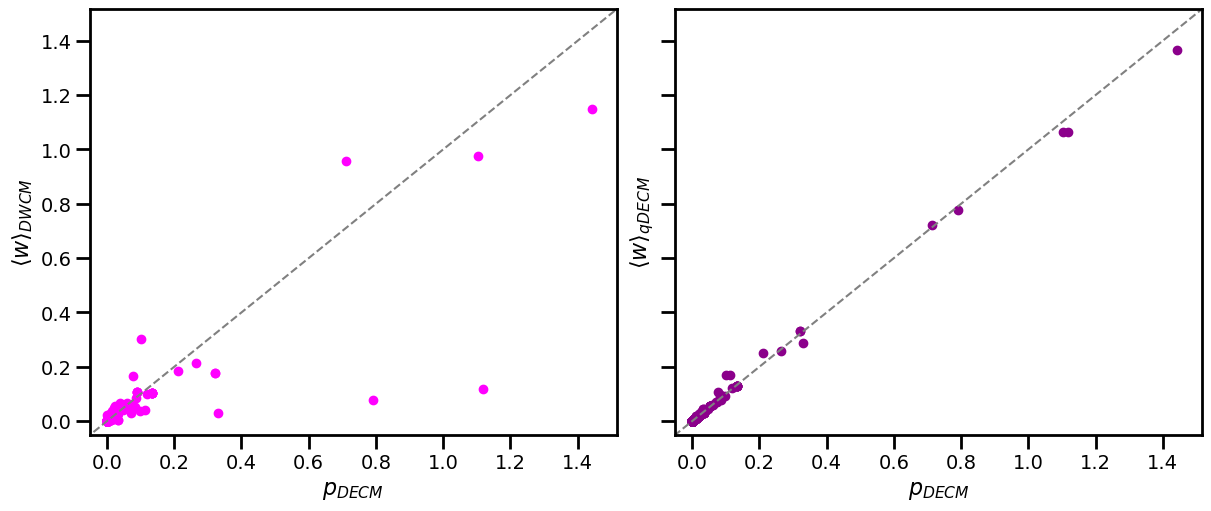

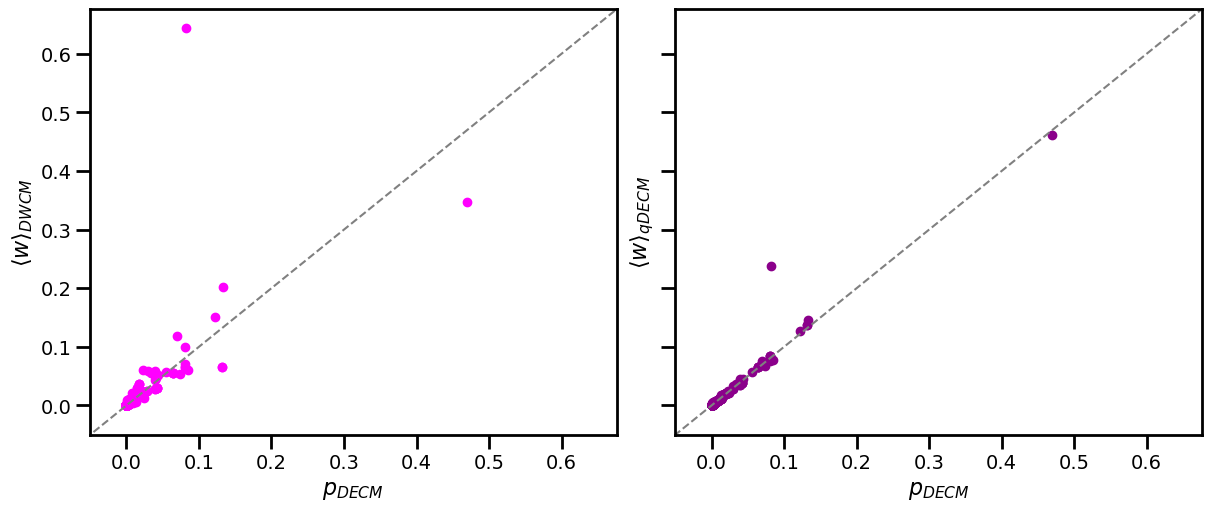

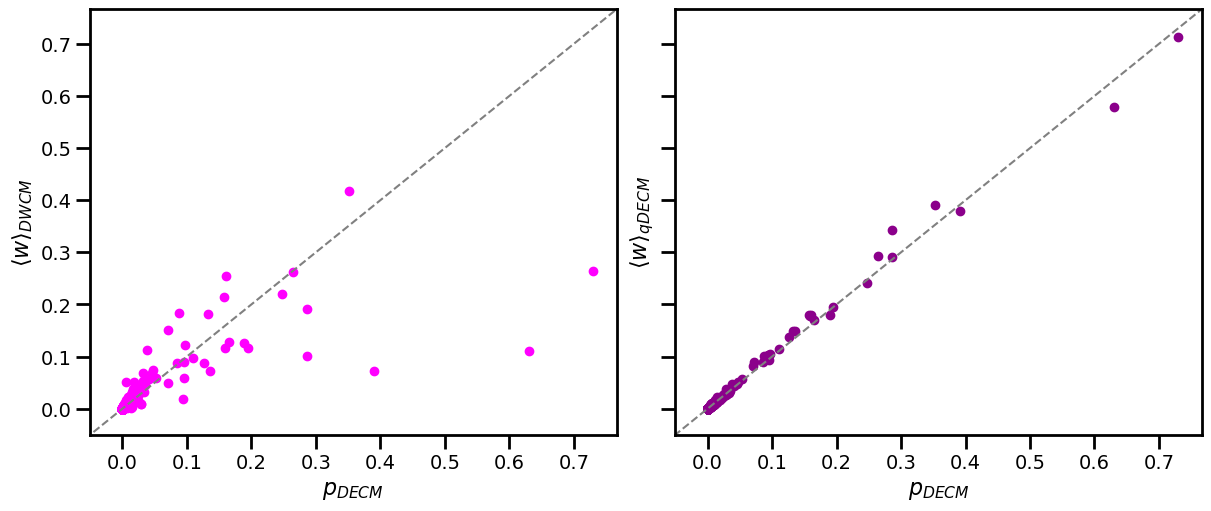

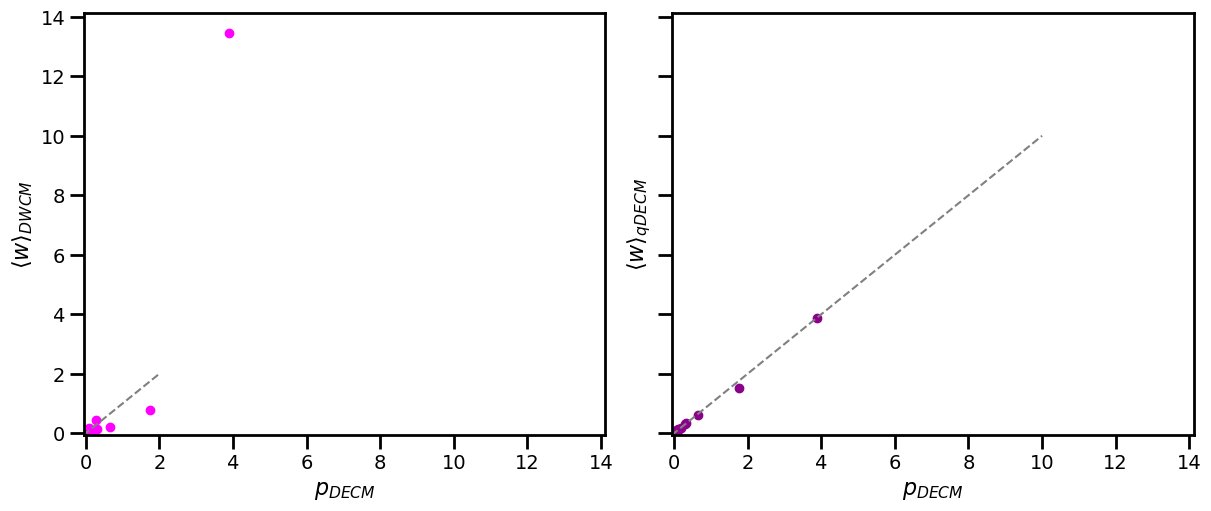

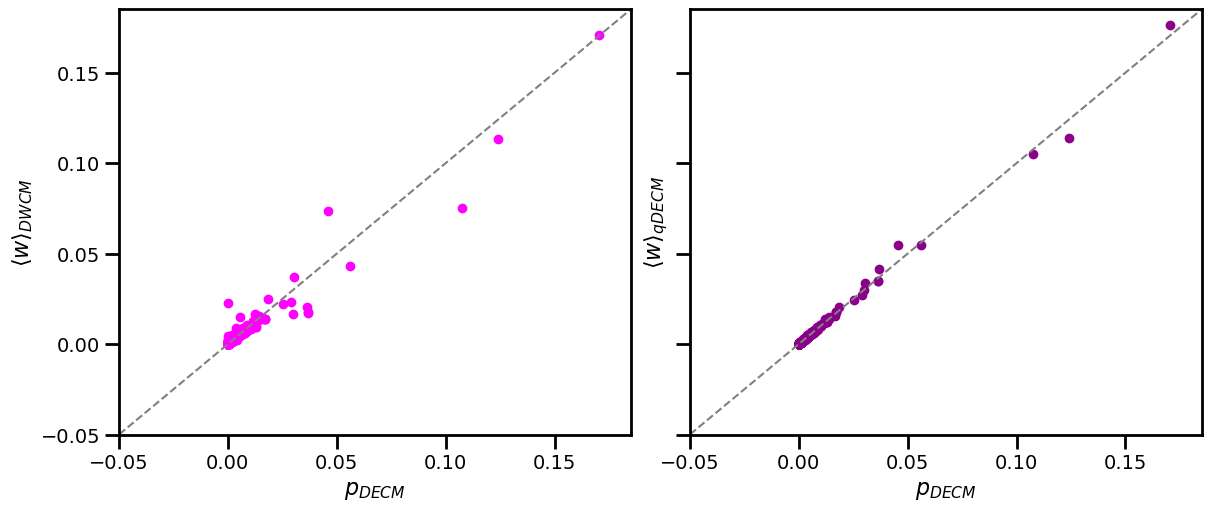

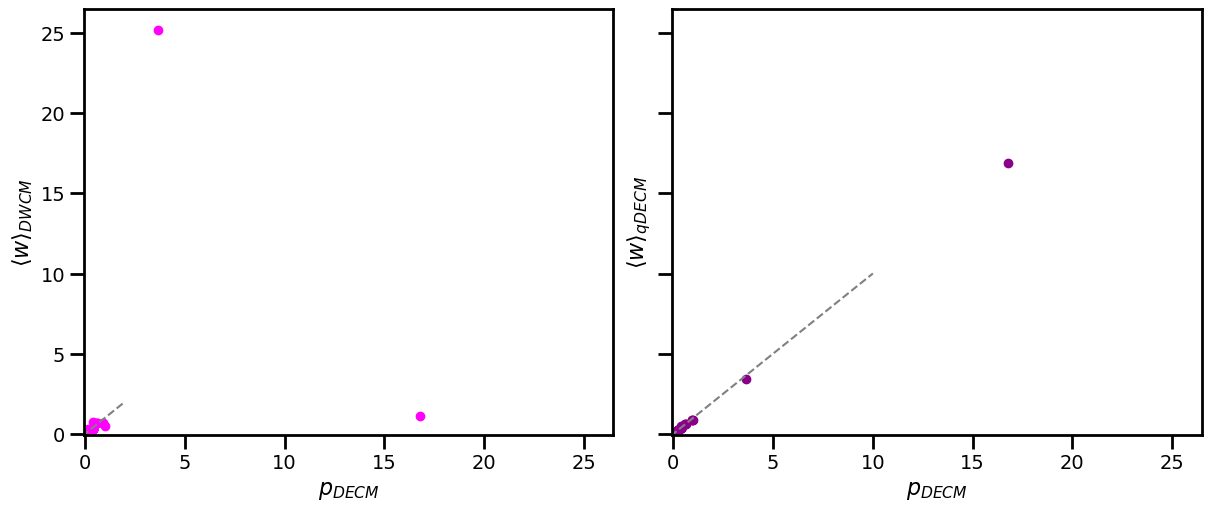

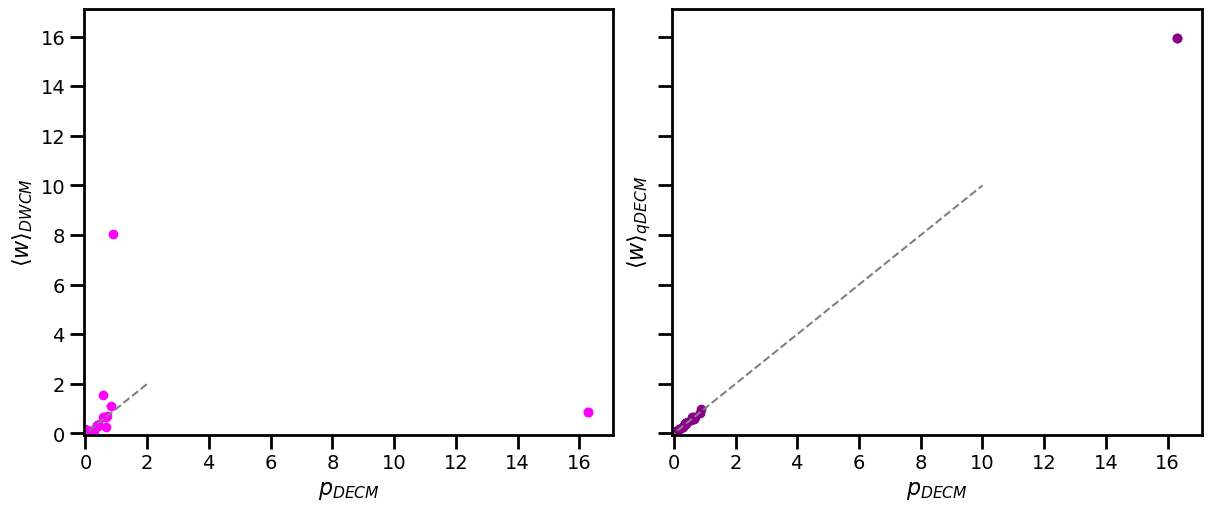

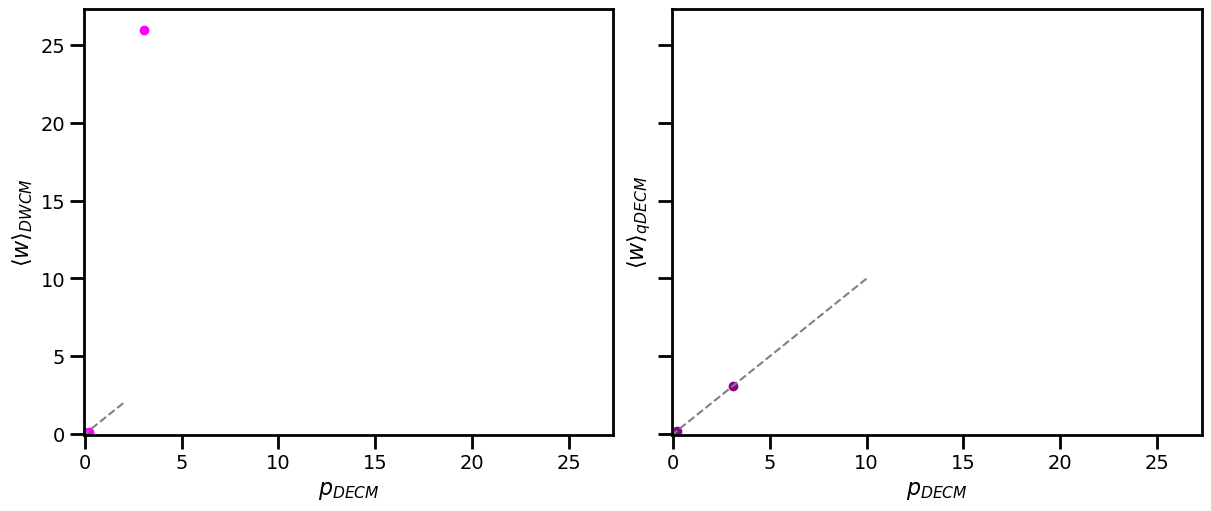

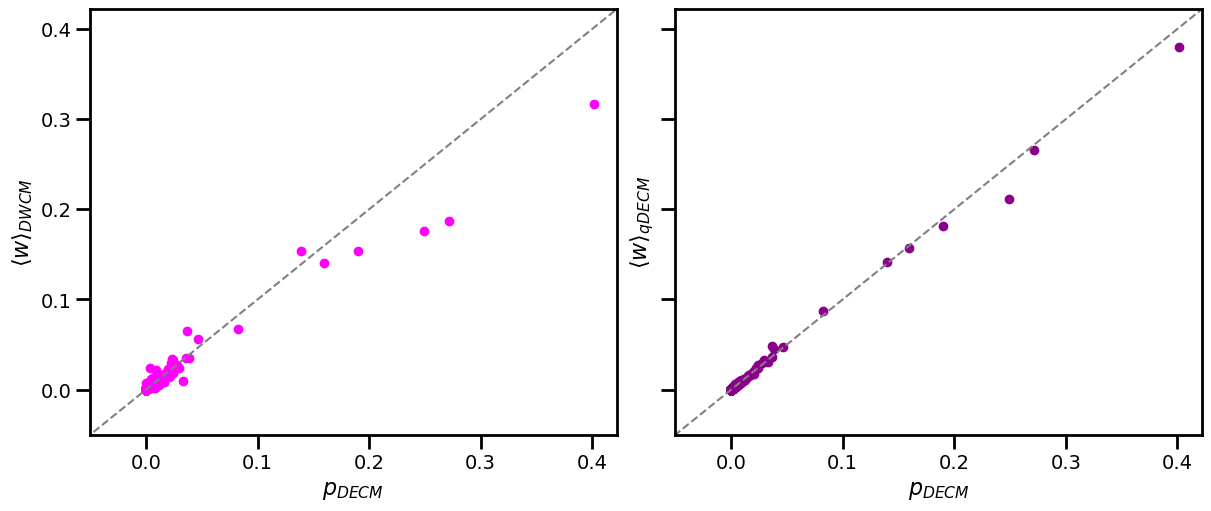

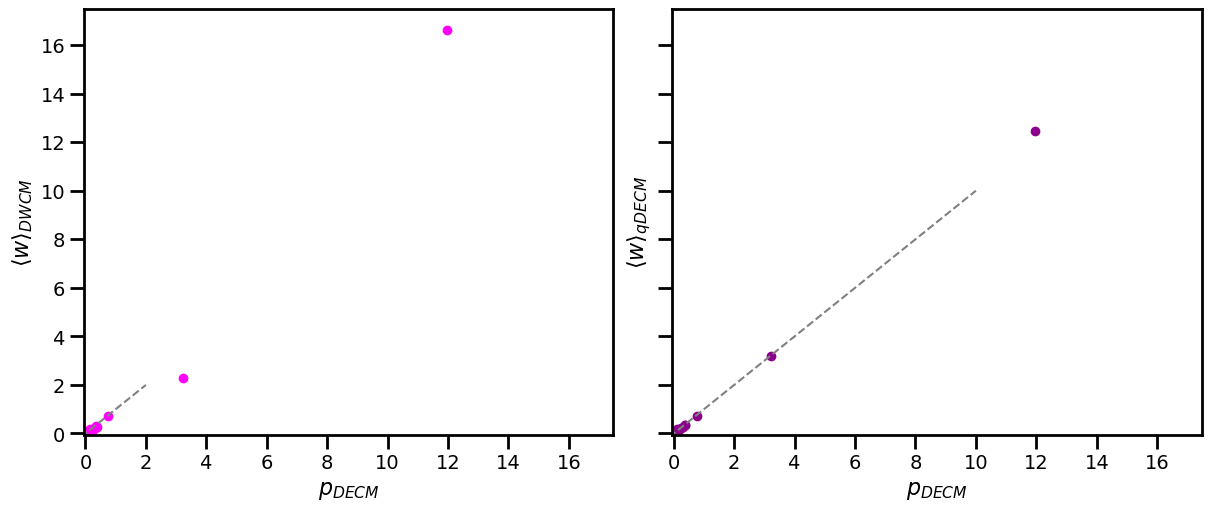

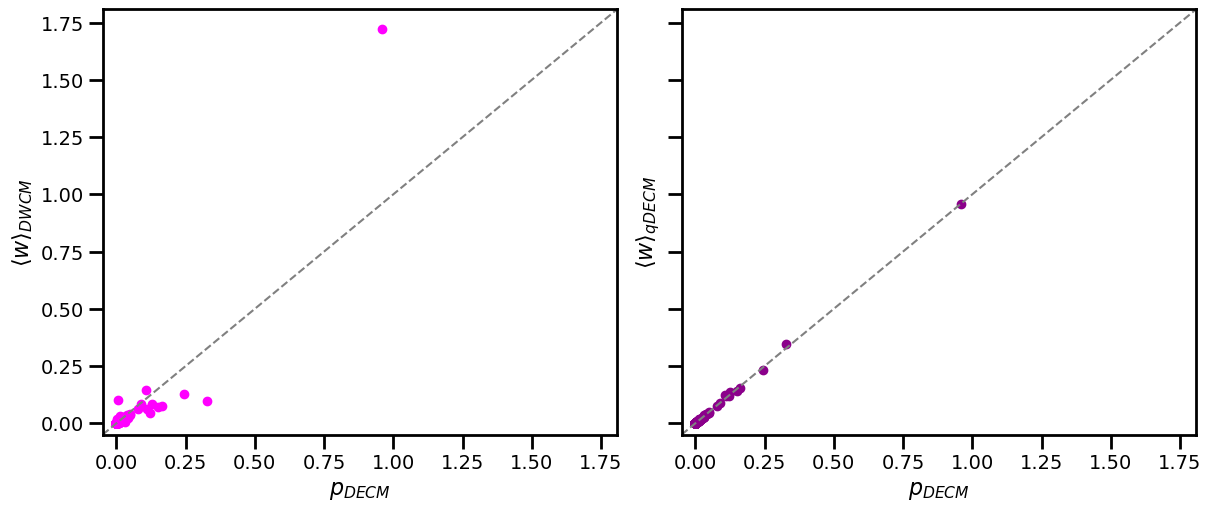

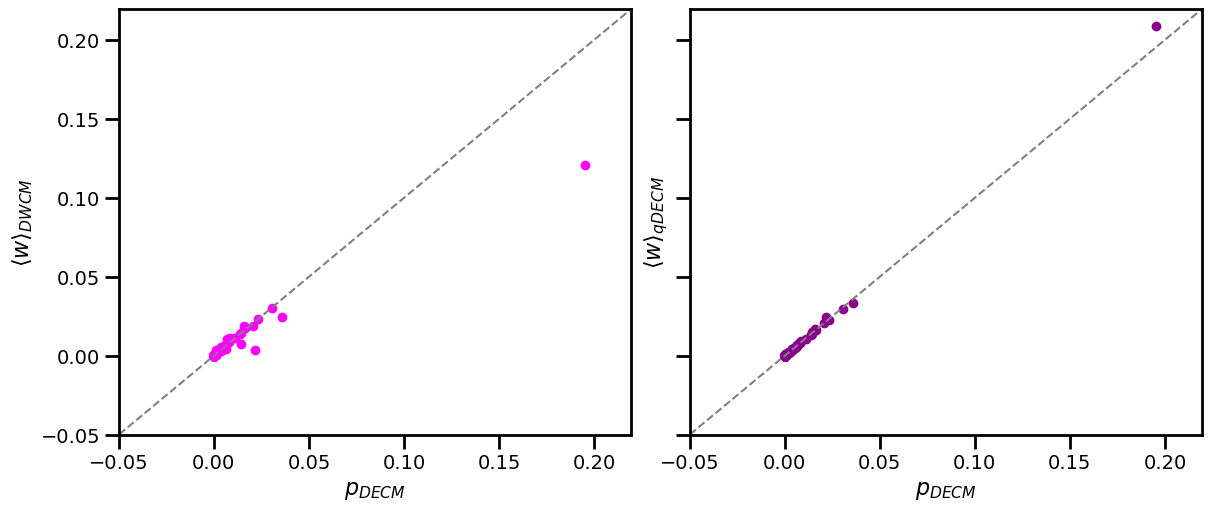

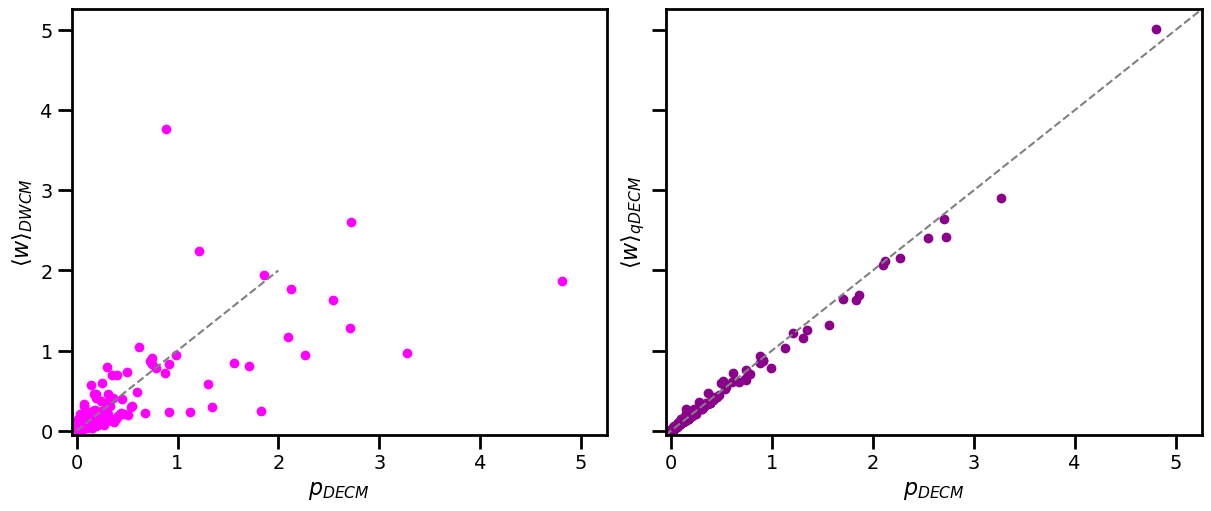

In [ ]:
for i in trange(len(_three_of_us)):
    dataset=_three_of_us[i]
    
    
    sol_dict=final_dict[dataset]

    # Check if all three models are present
    if not all(model in sol_dict for model in ['DECM', 'qDECM', 'DWCM']):
        msg="Dataset does not have all three models. Skipping."
        status(dataset, i, len(_three_of_us), msg)
        continue

    # Extract solutions
    decm_sol=sol_dict['DECM']
    qdecm_sol=sol_dict['qDECM']
    dwcm_sol=sol_dict['DWCM']
    N=decm_sol.N

    if N**2>10**9:
        msg=f"N={N:.2e} is too large, skipping dataset..."
        status(dataset, i, len(_three_of_us), msg)
        continue

    msg=f"N={N:.2e} Processing dataset..."
    status(dataset, i, len(_three_of_us), msg)
    # Now you can proceed with your analysis using decm_sol, qdecm_sol, and dwcm_sol
    theta_decm=decm_sol.sol.best_theta
    theta_qdecm=qdecm_sol.sol.best_theta
    theta_dwcm=dwcm_sol.sol.best_theta

    # select some of the entries
    msg=f"N={N:.2e} Selecting entries..."
    status(dataset, i+1, len(_three_of_us), msg)    
    selected_points=rng.choice(N**2, size=sample_size, replace=False)
    

    # probability matrices
    msg="Processing DECM..."
    status(dataset, i+1, len(_three_of_us), msg)    
    w_decm=decm_sol.wij_matrix(theta_decm).flatten()
    w_decm=w_decm[selected_points]

    msg="Processing qDECM..."
    status(dataset, i+1, len(_three_of_us), msg)    
    w_qdecm=qdecm_sol.wij_matrix_conditioned(theta_qdecm[:2*N], theta_qdecm[2*N:]).flatten()
    w_qdecm=w_qdecm[selected_points]

    msg="Processing DWCM..."
    status(dataset, i+1, len(_three_of_us), msg)        
    w_dwcm=dwcm_sol.wij_matrix(theta_dwcm).flatten()
    w_dwcm=w_dwcm[selected_points]

    max_p=np.max([w_decm.max(), w_qdecm.max(), w_dwcm.max()])

    
    msg="Points selected..."
    status(dataset, i+1, len(_three_of_us), msg)
    # plot
    fig, axs= plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True, sharex=True, sharey=True)

    axs[0].scatter(w_decm, w_dwcm, color=colors[0])
    axs[0].plot([-1,2*max_p], [-1,2*max_p], '--', color='gray')
    axs[0].set_xlim([-0.05, max_p*1.05])
    axs[0].set_ylim([-0.05, max_p*1.05])
    #axs[0].set_xscale('log')
    #axs[0].set_yscale('log')    

    axs[1].scatter(w_decm, w_qdecm, color=colors[1])
    axs[1].plot([-1,2*max_p], [-1,2*max_p], '--', color='gray')
    axs[1].set_xlim([-0.05, max_p*1.05])
    axs[1].set_ylim([-0.05, max_p*1.05])
    #axs[1].set_xscale('log')
    #axs[1].set_yscale('log')    


    for j in range(2):
        axs[j].set_xlabel(labels_decm[0], fontsize=16)
    axs[0].set_ylabel(labels_dwcm[1], fontsize=16)
    axs[1].set_ylabel(labels_qdecm[1], fontsize=16)
    plt.savefig(PLOT_FOLDER+f"w_comparison_{dataset}.png")
    msg="Plot saved!"
    status(dataset, i+1, len(_three_of_us), msg)

In [41]:
f"{final_dict['e0']['DECM'].N**2:.2e}"

'2.53e+09'

### Maximum "error"

In [ ]:
w_mask=w_decm>0
p_mask=p_decm>0

In [ ]:
torch.all(p_mask==w_mask)

tensor(True)

In [ ]:
w_mask.sum()

tensor(62285440)

In [ ]:
torch.all(p_qdecm[p_decm==0]==0)

tensor(True)

In [ ]:
torch.all(w_qdecm[w_decm==0]==0)

tensor(True)

So, all the zero entries of p(DECM) are also zero according to qDECM. Good...

### Maximum absolute and relative error on $p$

In [120]:
abs_error_p=torch.abs(p_decm[w_mask]-p_qdecm[w_mask])
torch.max(abs_error_p)

tensor(0.4593, dtype=torch.float64)

In [121]:
where_max_abs_err_p=torch.where(abs_error_p==torch.max(abs_error_p))[0][0]

In [122]:
p_decm[w_mask][where_max_abs_err_p], p_qdecm[w_mask][where_max_abs_err_p]

(tensor(0.7785, dtype=torch.float64), tensor(0.3192, dtype=torch.float64))

In [123]:
torch.max(abs_error_p)/p_decm[w_mask][where_max_abs_err_p]

tensor(0.5900, dtype=torch.float64)

In [124]:
rel_error_p=torch.abs(p_decm[w_mask]-p_qdecm[w_mask])/p_decm[w_mask]
torch.max(rel_error_p)

tensor(4.9443, dtype=torch.float64)

In [125]:
where_max_rel_err_p=torch.where(rel_error_p==torch.max(rel_error_p))[0][0]

In [126]:
p_decm[w_mask][where_max_rel_err_p], p_qdecm[w_mask][where_max_rel_err_p]

(tensor(0.0024, dtype=torch.float64), tensor(0.0142, dtype=torch.float64))

In [127]:
abs_error_p[where_max_rel_err_p]

tensor(0.0118, dtype=torch.float64)

### Maximum absolute and relative error on $w$

In [128]:
abs_error_w=torch.abs(w_decm[w_mask]-w_qdecm[w_mask])
torch.max(abs_error_w)

tensor(61.1904, dtype=torch.float64)

In [129]:
where_max_abs_err_w=torch.where(abs_error_w==torch.max(abs_error_w))[0][0]

In [130]:
w_decm[w_mask][where_max_abs_err_w], w_qdecm[w_mask][where_max_abs_err_w]

(tensor(253.9513, dtype=torch.float64), tensor(315.1417, dtype=torch.float64))

In [131]:
torch.max(abs_error_w)/w_decm[w_mask][where_max_abs_err_w]

tensor(0.2410, dtype=torch.float64)

In [132]:
rel_error_w=torch.abs(w_decm[w_mask]-w_qdecm[w_mask])/w_decm[w_mask]
torch.max(rel_error_w)

tensor(4.9422, dtype=torch.float64)

In [133]:
where_max_rel_err_w=torch.where(rel_error_w==torch.max(rel_error_w))[0][0]

In [134]:
w_decm[w_mask][where_max_rel_err_w], w_qdecm[w_mask][where_max_rel_err_w]

(tensor(0.0024, dtype=torch.float64), tensor(0.0143, dtype=torch.float64))

In [135]:
abs_error_w[where_max_rel_err_w]

tensor(0.0119, dtype=torch.float64)

In [136]:
where_max_rel_err_w, where_max_rel_err_p

(tensor(45332149), tensor(45332149))

This is quite suspect...

# Summarising
1. so far, all algorithms follows a local Newton method, i.e. a Newton in which, instead of calculating the inverse of the Hessian, all entries are considered as independent (they are not). It works on every models for all datasets, but for DECM; In the cas eof DECM, it properly works on all test datasets (i.e. N~10k).
2. the only empirical network on which the DECM converge is crisis dico2. It converged by accident: the evolution of the MRE jumps around savagely until it find the proper path and then converges immediately. The same procedure was applied with no success on other dataset. All other tricks (backtracking, 2x2, different update phases) implemented did not work;
3. on crisi dico2 differences are impressive: the relative error on both the expected weights and the expected topology (i.e. $p$) is up to 5 (I mean, 500%), which is quite high. **A proper comparison should show how the p-value calculated with DECM and qDECM differ for our case, i.e. for the validation of the fluxes and the dimension of the blocks in the bowtie**; 
4. as DECM seems to goverge _extremely slowly_ to the proper solution, I can decide that I can wait for a couple of datasets considered as benchmarks, i.e. IV and DX (as they have the most marked bowtie structure) for the dataset used as benchmark, i.e. ita_elections. 
5. the likelihood, as calculated so far, needs to be checked. Consider also that on the networks that we decide to use as benchmarks, a model selection should be run **and** a fine justification for using qDECM instead of DECM should be found, even if BIC could never win (unless we used the _ad hoc_ defined generalized likelihood). **Update**: DWCM wins the BIC competition. _What?!?_ Probably many zeros are returned also by DWCM without involving more complicated models. Nevertheless, such a result is a mess. More investigations are needed, probably on other datasets and dicos...
6. Hooray! o_o